# Severidad truncada, cola empalmada y umbral: ajustar lo que permiten los datos

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (la pérdida anual como frecuencia por severidad)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar por qué un banco que registra solo las pérdidas sobre un umbral de recolección debe ajustar una severidad truncada y reescalar su frecuencia, y mostrar con el motor el sesgo de ignorarlo;
- ajustar una lognormal, una cola Pareto generalizada y un empalme de cuerpo lognormal y cola Pareto a las pérdidas registradas de una historia simulada, y leer sus parámetros y errores estándar;
- leer el perfil del índice de cola a través de umbrales y la prueba `oprisk.threshold_stability`;
- explicar, desde los documentos versionados, por qué el índice de cola del generador es el que mejor reproduce los percentiles de la LDCE de Basilea, y por qué varios de estos ajustes son inestables con una historia de diez años.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El generador del caso C17 y sus estimadores viven en `data-pipeline/pipeline/cases/c17/`, que no es un paquete instalado: este cuaderno carga esos módulos por su ruta (importar todo el paquete `pipeline` importaría todos los casos y sus dependencias pesadas). La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import distributions
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las cuatro variantes del caso C17 (índices de cola 0,6, 0,8, 0,96 y 1,1) y el documento del generador que las reúne. El caso construye un banco sintético cuyas pérdidas siguen un conteo Poisson y un monto Pareto generalizado sobre un piso de EUR 10.000; sus parámetros se ajustan a cuatro percentiles del Ejercicio de Recolección de Datos de Pérdida de 2008 del Comité de Basilea (BCBS, 2009; `derived-only`). Como la verdad es conocida, cada ajuste de abajo se puede juzgar frente a ella.

- **Archivos que se leen:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json`, `xi-1-1.json` (claves `outputs.calibration` y `outputs.cells`) y `data/derived/C17/models-generator.json` (los objetivos de la LDCE).
- **Una historia:** los documentos versionados guardan resúmenes sobre 1.000 historias, no las historias. Este cuaderno sortea una historia de la variante con índice de cola 0,8 con el generador propio del caso, cargado por su ruta, y con una semilla tomada del rango de semillas del caso. Una historia es función pura de su semilla, así que cualquiera obtiene las mismas pérdidas.

La celda siguiente carga los documentos e imprime los objetivos de la LDCE a los que se calibra el generador.

In [2]:
# Load the four variant documents and the generator document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C17 = ROOT / "data" / "derived" / "C17"
variants = {name: json.loads((C17 / (name + ".json")).read_text(encoding="utf-8")) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")}
generator_doc = json.loads((C17 / "models-generator.json").read_text(encoding="utf-8"))

targets = generator_doc["fit"]["calibration"]
print("fuente:", targets["source"]["id"], "| tabla", targets["source"]["table"], "| clase de licencia", targets["licence_class"])
print("frecuencia mediana de la LDCE por EUR mil millones de activos (pérdidas de EUR 20000 o más):", targets["frequency"]["per_eur_bn_assets"])
for point in targets["severity_percentiles"]:
    print("percentil de la LDCE %.2f: EUR %s" % (point["p"], format(point["loss_eur"], ",")))

fuente: bcbs160 | tabla ILD7 | clase de licencia derived-only
frecuencia mediana de la LDCE por EUR mil millones de activos (pérdidas de EUR 20000 o más): 0.82
percentil de la LDCE 0.25: EUR 27,632
percentil de la LDCE 0.50: EUR 41,916
percentil de la LDCE 0.75: EUR 82,608
percentil de la LDCE 0.95: EUR 418,400


A continuación, el generador. El módulo `generator.py` del propio caso sortea una historia a partir de una semilla y `params.py` guarda las constantes del caso. Se cargan por su ruta bajo un nombre de paquete desechable, para no importar nada más del pipeline; `sys.dont_write_bytecode` evita que la importación deje archivos de caché en el repositorio. La celda imprime los parámetros verdaderos de la variante con índice de cola 0,8.

In [3]:
# Load the generator and its parameters from data-pipeline/ by path (the pipeline package is not imported as a whole)
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params

variant = generator.variant(0.8)
print("índice de cola verdadero:", variant.tail_index, "| escala verdadera sobre el piso (EUR):", round(variant.scale_eur, 4))
print("pérdidas verdaderas al año sobre el piso de EUR", int(case_params.FLOOR_EUR), ":", round(variant.lambda_per_year, 4))

índice de cola verdadero: 0.8 | escala verdadera sobre el piso (EUR): 17744.2063
pérdidas verdaderas al año sobre el piso de EUR 10000 : 65.2849


## Método

Seguimos a un banco a lo largo de la estimación, en siete pasos. El paso 1 es de dónde sale la severidad verdadera; los pasos 2 a 6 ajustan lo que un banco registra a partir de una historia de diez años; el paso 7 pregunta hasta dónde se puede confiar en esos ajustes.

### Paso 1: de dónde sale el índice de cola verdadero

El generador sortea cada pérdida de una distribución Pareto generalizada sobre su piso $u$ = EUR 10.000 (Chavez-Demoulin, Embrechts y Neslehova, 2006). La LDCE publica percentiles de las pérdidas sobre EUR 20.000, y una distribución Pareto generalizada condicionada a superar un umbral mayor $H$ es de nuevo Pareto generalizada, con el mismo índice de cola y una escala desplazada:

$$P(X > x \mid X > H) = \left(1 + \xi \, \frac{x - H}{\beta + \xi\,(H - u)}\right)^{-1/\xi}, \qquad \beta_H = \beta + \xi\,(H - u)$$

Para un $\xi$ dado, el caso elige la escala por mínimos cuadrados sobre los logaritmos de los excesos sobre EUR 20.000 en los cuatro percentiles $p_j$ de la LDCE con objetivos $t_j$ (el ajuste del dossier de investigación sobre riesgo operacional, sección F.6):

$$\min_{\beta}\; \sum_{j=1}^{4} \left[\ln\!\big(q_{\xi,\beta_H}(p_j) - H\big) - \ln\!\big(t_j - H\big)\right]^2, \qquad H = 20.000$$

La celda siguiente recalcula, para cada una de las cuatro variantes, los cuantiles ajustados a partir de la escala versionada con `severity_ppf` del motor, usando el $\beta_H$ de arriba, e imprime el mayor error logarítmico absoluto que registra el documento.

In [4]:
# Recompute the fitted LDCE quantiles of each variant from its committed scale, and read the recorded fit error
H_LDCE = 20_000.0
p_ldce = np.array([point["p"] for point in targets["severity_percentiles"]])
t_ldce = np.array([point["loss_eur"] for point in targets["severity_percentiles"]], dtype=float)
print("objetivos de la LDCE:", t_ldce)
for name, doc in variants.items():
    fit = doc["outputs"]["calibration"]["fit"]
    xi, beta = fit["tail_index"], fit["scale_eur"]
    beta_h = beta + xi * (H_LDCE - 10_000.0)
    fitted = distributions.severity_ppf("gpd", (xi, beta_h, H_LDCE), p_ldce)
    log_err = np.log(fitted - H_LDCE) - np.log(t_ldce - H_LDCE)
    print("xi = %-4s | beta_H = %9.2f | ajustados %s | error log. abs. máx., recalculado %.4f | registrado %.4f"
          % (xi, beta_h, np.round(fitted).astype(int), np.abs(log_err).max(), fit["max_abs_log_error"]))

objetivos de la LDCE: [ 27632.  41916.  82608. 418400.]
xi = 0.6  | beta_H =  30381.85 | ajustados [ 29540  46114  85696 274913] | error log. abs. máx., recalculado 0.4465 | registrado 0.4465
xi = 0.8  | beta_H =  25744.21 | ajustados [ 28328  43849  85372 341339] | error log. abs. máx., recalculado 0.2150 | registrado 0.2150
xi = 0.96 | beta_H =  22423.68 | ajustados [ 27430  42081  85034 411047] | error log. abs. máx., recalculado 0.0380 | registrado 0.0380
xi = 1.1  | beta_H =  19797.32 | ajustados [ 26700  40581  84698 487678] | error log. abs. máx., recalculado 0.1603 | registrado 0.1603


### Paso 2: lo que el banco registra de una historia

Un banco que recolecta pérdidas solo desde EUR 20.000 nunca ve las menores. `draw_history`, del generador, devuelve todas las pérdidas que el banco sufrió en $Y$ años; `recorded(H)` conserva las que están en el umbral de recolección $H$ o sobre él y entrega además el conteo de cada año. Todo estimador de abajo lee solo las pérdidas registradas. La celda siguiente sortea diez años e imprime cuántas pérdidas se sufrieron y cuántas registra el banco.

In [5]:
# Draw one history of ten years and keep what a bank with a collection threshold of EUR 20,000 records
SEED, YEARS, H = 4208002, 10, 20_000.0
history = generator.draw_history(variant, SEED, YEARS)
recorded = history.recorded(H)
print("pérdidas sufridas en", YEARS, "años:", history.amount_eur.size, "| registradas sobre EUR", int(H), ":", recorded.amounts.size)
print("conteos anuales de pérdidas registradas:", recorded.counts)
print("menor y mayor pérdida registrada (EUR):", round(recorded.amounts.min()), round(recorded.amounts.max()))

pérdidas sufridas en 10 años: 673 | registradas sobre EUR 20000 : 422
conteos anuales de pérdidas registradas: [38 47 35 40 48 35 42 47 47 43]
menor y mayor pérdida registrada (EUR): 20020 8326644


### Paso 3: la frecuencia

Para un conteo Poisson, la estimación de máxima verosimilitud de la tasa es la media de los conteos anuales y su error estándar es $\sqrt{\hat\lambda / Y}$. `fit_frequency`, del motor, devuelve ambos. El generador nos dice el número esperado verdadero de pérdidas al año en EUR 20.000 o más, así que podemos ver cuánto se acercan diez años.

In [6]:
# Fit the Poisson rate of the recorded counts and compare it with the true expected count above the threshold
freq_fit = distributions.fit_frequency(recorded.counts)
lam_obs = freq_fit.params[0]
print("tasa estimada:", round(lam_obs, 4), "| error estándar:", round(freq_fit.std_errors[0], 4))
print("media de los conteos:", recorded.counts.mean(), "| sqrt(lambda/Y):", round(float(np.sqrt(recorded.counts.mean() / YEARS)), 4))
print("pérdidas anuales esperadas verdaderas desde EUR", int(H), ":", round(generator.expected_count_above(variant, H), 4))

tasa estimada: 42.2 | error estándar: 2.0543
media de los conteos: 42.2 | sqrt(lambda/Y): 2.0543
pérdidas anuales esperadas verdaderas desde EUR 20000 : 41.0


### Paso 4: la severidad, con y sin truncamiento

Si el banco ajusta una lognormal a las pérdidas registradas como si fueran todas sus pérdidas, la verosimilitud es $\sum_i \ln f(x_i)$ y el ajuste describe las pérdidas sobre $H$ como si nada hubiera debajo. La verosimilitud correcta para pérdidas registradas sobre $H$ condiciona al registro (Mignola y Ugoccioni, 2007; Chavez-Demoulin, Embrechts y Neslehova, 2006):

$$\ell(\theta) = \sum_{i=1}^{N} \ln f(x_i \mid \theta) \;-\; N \ln\big(1 - F(H \mid \theta)\big)$$

El segundo término es lo que agrega el truncamiento: la ley ajustada debe explicar por qué solo vemos lo que está sobre $H$. `fit_severity` hace ambos con `truncated=False` o `True`. La celda siguiente ajusta los dos, imprime sus parámetros, errores estándar y log-verosimilitudes, y compara la mediana implícita de una pérdida registrada con la mediana muestral.

In [7]:
# Fit the lognormal ignoring and modelling the threshold, and print what each fit holds
fit_ignoring = distributions.fit_severity("lognormal", recorded.amounts, H, truncated=False)
fit_truncated = distributions.fit_severity("lognormal", recorded.amounts, H, truncated=True)
for label, fit in (("ignorando el umbral", fit_ignoring), ("truncada en el umbral", fit_truncated)):
    print("%-28s mu = %9.4f (se %.4f) | sigma = %.4f (se %.4f) | loglik = %.2f | convergió %s"
          % (label, fit.params[0], fit.std_errors[0], fit.params[1], fit.std_errors[1], fit.loglik, fit.converged))
print("mediana muestral de las pérdidas registradas (EUR):", round(float(np.median(recorded.amounts))))
median_ignoring = float(distributions.severity_ppf("lognormal", fit_ignoring.params, np.array([0.5]))[0])
tail_prob = 1.0 - float(distributions.severity_cdf("lognormal", fit_truncated.params, np.array([H]))[0])
median_truncated = float(distributions.severity_ppf("lognormal", fit_truncated.params, np.array([1.0 - tail_prob / 2.0]))[0])
print("mediana implícita, ignorando el umbral (EUR):", round(median_ignoring), "| mediana implícita, truncada (EUR):", round(median_truncated))

ignorando el umbral          mu =   10.9574 (se 0.0456) | sigma = 0.9366 (se 0.0322) | loglik = -5195.18 | convergió True
truncada en el umbral        mu =    5.8013 (se 2.5993) | sigma = 2.5123 (se 0.5544) | loglik = -5064.90 | convergió True
mediana muestral de las pérdidas registradas (EUR): 43962
mediana implícita, ignorando el umbral (EUR): 57379 | mediana implícita, truncada (EUR): 44298


### Paso 5: la frecuencia hay que reescalarla

Un ajuste truncado describe solo las pérdidas sobre $H$, así que la tasa observada sobre $H$ no es la tasa de la severidad completa. La probabilidad de que una pérdida de la ley ajustada supere $H$ es $1 - F(H)$, y la tasa de todas las pérdidas de la ley ajustada es la observada dividida por ella (Mignola y Ugoccioni, 2007):

$$\lambda_{\text{full}} = \frac{\lambda_{\text{obs}}}{1 - F(H)}$$

`rescale_frequency` la calcula. El número solo tiene sentido con la severidad de la que salió: una verdad de cola pesada ajustada con una lognormal exige un $1 - F(H)$ minúsculo, así que $\lambda_{\text{full}}$ es enorme y cuenta pérdidas de todo tamaño hasta cero. La celda siguiente imprime cada factor de la fórmula y luego el número esperado de pérdidas al año sobre EUR 10.000 que implica el ajuste, para compararlo con la tasa verdadera del generador ahí.

In [8]:
# Rescale the observed rate by the engine and show the factors of the formula
cdf_at_h = float(distributions.severity_cdf("lognormal", fit_truncated.params, np.array([H]))[0])
lam_full = distributions.rescale_frequency(lam_obs, "lognormal", fit_truncated.params, H)
print("lambda_obs:", round(lam_obs, 4), "| F(H):", round(cdf_at_h, 6), "| 1 - F(H):", round(1.0 - cdf_at_h, 6))
print("lambda_obs / (1 - F(H)):", round(lam_obs / (1.0 - cdf_at_h), 2), "| motor:", round(lam_full, 2))
cdf_at_floor = float(distributions.severity_cdf("lognormal", fit_truncated.params, np.array([case_params.FLOOR_EUR]))[0])
print("pérdidas anuales implícitas sobre EUR 10000:", round(lam_full * (1.0 - cdf_at_floor), 2), "| verdadero:", round(variant.lambda_per_year, 2))

lambda_obs: 42.2 | F(H): 0.948752 | 1 - F(H): 0.051248
lambda_obs / (1 - F(H)): 823.45 | motor: 823.45
pérdidas anuales implícitas sobre EUR 10000: 71.97 | verdadero: 65.28


### Paso 6: ¿la ley truncada describe las pérdidas registradas?

La distribución de una pérdida registrada es la ley ajustada condicionada a superar $H$:

$$F_H(x) = \frac{F(x) - F(H)}{1 - F(H)}, \qquad x \ge H$$

`truncated_severity_cdf` la devuelve. Una verificación directa frente a los datos es ponerla junto a la proporción empírica de pérdidas registradas iguales o menores a algunos montos. Es una verificación del ajuste, no una segunda implementación de la verosimilitud.

In [9]:
# Compare the truncated distribution function of the fit with the empirical one of the recorded losses
grid = np.array([30_000.0, 50_000.0, 100_000.0, 500_000.0, 1_000_000.0])
model_cdf = distributions.truncated_severity_cdf("lognormal", fit_truncated.params, grid, H)
empirical = np.array([(recorded.amounts <= x).mean() for x in grid])
print("%12s %14s %14s" % ("x (EUR)", "modelo", "empírica"))
for x, m, e in zip(grid, model_cdf, empirical):
    print("%12s %14.4f %14.4f" % (format(x, ",.0f"), m, e))

     x (EUR)         modelo       empírica
      30,000         0.2900         0.2559
      50,000         0.5535         0.5782
     100,000         0.7756         0.7844
     500,000         0.9652         0.9621
   1,000,000         0.9861         0.9810


### Paso 7: la cola, un ajuste Pareto generalizado y el empalme

Una cola lognormal decae más rápido que una ley de potencia, y los datos de un banco con índice de cola cercano a 1 se parecen a una ley de potencia. Dos respuestas estándar son un ajuste Pareto generalizado a los excesos sobre un umbral, que hace `fit_severity("gpd", ...)` (la ubicación es el umbral de recolección), y un **empalme**: un cuerpo lognormal bajo un umbral de empalme $u_s$ y una cola Pareto generalizada sobre él (Chavez-Demoulin, Embrechts y Neslehova, 2006), con peso del cuerpo $w = P(X \le u_s)$ y densidad

$$f(x) = w\,\frac{f_b(x)}{F_b(u_s)} \;\; (x \le u_s), \qquad f(x) = (1 - w)\, g_{\xi,\beta}(x - u_s) \;\; (x > u_s)$$

donde $f_b$ es la densidad lognormal, $F_b$ su función de distribución y $g_{\xi,\beta}$ la densidad de la Pareto generalizada. `fit_splice` ajusta ambas partes en un umbral de empalme que fija quien llama (aquí EUR 100.000, la elección del caso) y deriva $w$ de la proporción observada de la cola. La celda siguiente ajusta las tres severidades e imprime, en cinco montos, la probabilidad de que una pérdida registrada los supere: la verdad, la lognormal truncada, la Pareto generalizada, el empalme y la proporción empírica.

In [10]:
# Fit the generalised Pareto tail and the splice, then compare the survival of a recorded loss at five amounts
SPLICE_AT = case_params.SPLICE_THRESHOLD_EUR
fit_gpd = distributions.fit_severity("gpd", recorded.amounts, H, truncated=True)
fit_splice = distributions.fit_splice(recorded.amounts, H, SPLICE_AT)
print("GPD: xi = %.4f (se %.4f) | beta = %.1f (se %.1f) | xi verdadero %.2f" % (fit_gpd.params[0], fit_gpd.std_errors[0], fit_gpd.params[1], fit_gpd.std_errors[1], variant.tail_index))
mu, sigma, u_s, xi_s, beta_s, weight = fit_splice.params
print("empalme: mu = %.3f | sigma = %.3f | xi = %.4f | beta = %.1f | w = %.4f | pérdidas del cuerpo %d | pérdidas de la cola %d | convergió %s"
      % (mu, sigma, xi_s, beta_s, weight, fit_splice.n_body, fit_splice.n_tail, fit_splice.converged))

amounts = np.array([50_000.0, 100_000.0, 500_000.0, 1_000_000.0, 5_000_000.0])


def survival_given_recorded(law, params):
    # the probability that a loss exceeds each amount, given that it exceeds the collection threshold
    sf = 1.0 - distributions.severity_cdf(law, params, amounts)
    return sf / (1.0 - float(distributions.severity_cdf(law, params, np.array([H]))[0]))


table = {
    "verdad": survival_given_recorded("gpd", variant.sev_params),
    "lognormal truncada": survival_given_recorded("lognormal", fit_truncated.params),
    "GPD": survival_given_recorded("gpd", fit_gpd.params),
    "empalme": survival_given_recorded("lognormal-gpd-splice", fit_splice.params),
    "empírica": np.array([(recorded.amounts > x).mean() for x in amounts]),
}
print("%-22s" % "x (EUR)", " ".join("%10s" % format(x, ",.0f") for x in amounts))
for label, values in table.items():
    print("%-22s" % label, " ".join("%10.5f" % v for v in values))
sf_ignoring = 1.0 - distributions.severity_cdf("lognormal", fit_ignoring.params, amounts)
print("%-22s" % "lognormal, ignorando", " ".join("%10.5f" % v for v in sf_ignoring), "(incondicional)")

GPD: xi = 0.8035 (se 0.0862) | beta = 26796.5 (se 2436.8) | xi verdadero 0.80
empalme: mu = 9.825 | sigma = 1.098 | xi = 0.9112 | beta = 84402.0 | w = 0.8928 | pérdidas del cuerpo 331 | pérdidas de la cola 91 | convergió True
x (EUR)                    50,000    100,000    500,000  1,000,000  5,000,000
verdad                    0.43896    0.20994    0.03146    0.01343    0.00182
lognormal truncada        0.44646    0.22436    0.03480    0.01388    0.00125
GPD                       0.44998    0.21813    0.03329    0.01428    0.00195
empalme                   0.44631    0.21564    0.03445    0.01597    0.00271
empírica                  0.42180    0.21564    0.03791    0.01896    0.00237
lognormal, ignorando      0.55842    0.27655    0.01040    0.00114    0.00000 (incondicional)


### Paso 8: el perfil del índice de cola a través de umbrales

Si el modelo Pareto generalizado fuera exacto, el índice de cola ajustado sobre cualquier umbral estimaría el mismo número. `tail_index_profile` lo ajusta en una lista de umbrales; el caso usa 1, 2, 4 y 8 veces el umbral de recolección (Chavez-Demoulin, Embrechts y Neslehova, 2006). Menos excesos en los umbrales altos vuelven cada ajuste más ruidoso, así que el perfil es un intercambio entre el sesgo de un umbral bajo y la varianza de uno alto. La prueba del motor `oprisk.threshold_stability` resume un perfil por su **rango** (máximo menos mínimo de los índices de cola finitos) frente a dos umbrales de decisión de Contraste, 0,10 para verde y 0,25 para ámbar; son umbrales internos del caso, no umbrales regulatorios. La celda siguiente ajusta el perfil de nuestra historia y corre la prueba, y luego imprime el perfil versionado sobre 1.000 historias de la misma celda (10 años, umbral EUR 20.000).

In [11]:
# Fit the tail-index profile of this history, run the stability test, and read the committed profile of the same cell
multiples = np.array([1.0, 2.0, 4.0, 8.0])
profile = distributions.tail_index_profile(recorded.amounts, H * multiples)
xi_profile = np.where(profile.converged, profile.xi, np.nan)
stability = oprisk_tests.threshold_stability(profile.thresholds, xi_profile, model_id="lda-splice")
cell = next(c for c in variants["xi-0-8"]["outputs"]["cells"] if c["id"] == "y10-h20000")
print("%12s %12s %8s %8s | versionado sobre 1000 historias: p05, mediana, p95" % ("umbral", "excesos", "xi", "se"))
for k, (u, n, xi_hat, se) in enumerate(zip(profile.thresholds, profile.n_exceedances, profile.xi, profile.xi_se)):
    row = cell["threshold_stability"][k]["tail_index"]
    print("%12s %12d %8.4f %8.4f | %.3f %.3f %.3f" % (format(u, ",.0f"), n, xi_hat, se, row["p05"], row["median"], row["p95"]))
print("rango del perfil:", round(stability.metric, 4), "| luz:", stability.light.value, "| umbrales:", stability.extras["thresholds"])
print("calculado por riskvalidation", variants["xi-0-8"]["provenance"]["riskvalidation_version"], "| instalado", md.version("riskvalidation"))

      umbral      excesos       xi       se | versionado sobre 1000 historias: p05, mediana, p95
      20,000          422   0.8035   0.0862 | 0.646 0.799 0.940
      40,000          236   0.9138   0.1283 | 0.592 0.792 0.996
      80,000          118   0.8822   0.1707 | 0.492 0.786 1.054
     160,000           53   0.8736   0.2511 | 0.335 0.780 1.221
rango del perfil: 0.1104 | luz: amber | umbrales: {'tol_green': 0.1, 'tol_amber': 0.25}
calculado por riskvalidation 0.7.0 | instalado 0.8.1


### Paso 9: ¿cuán estables son estos ajustes?

Una historia es un sorteo. Los documentos versionados registran, para cada peldaño de la escalera, en cuántas de las 1.000 historias de una celda se pudo ajustar. La celda siguiente ajusta la lognormal truncada y el empalme en doce historias consecutivas de la celda (semillas 4208000 a 4208011) e imprime los parámetros de la lognormal y el peso del cuerpo del empalme, y luego el número versionado de historias en que cada peldaño está definido, para los cuatro índices de cola. Un peso de empalme de 1 o una ubicación lognormal muy lejos del logaritmo de las pérdidas significa que el cuerpo del ajuste colapsó a una ley degenerada que los datos no logran fijar.

In [12]:
# Fit the truncated lognormal and the splice on twelve consecutive histories of the cell, then read the committed counts of defined rungs
print("%8s %7s %10s %9s %9s %12s" % ("semilla", "pérdidas", "mu", "sigma", "w", "convergió"))
for seed in range(4208000, 4208012):
    rec = generator.draw_history(variant, seed, YEARS).recorded(H)
    ln = distributions.fit_severity("lognormal", rec.amounts, H, truncated=True)
    sp = distributions.fit_splice(rec.amounts, H, SPLICE_AT)
    print("%8d %7d %10.2f %9.3f %9.4f %12s" % (seed, rec.amounts.size, ln.params[0], ln.params[1], sp.weight, sp.converged))
print()
print("versionado: historias (de 1000) en que el peldaño está definido, celda y10-h20000")
for name, doc in variants.items():
    cap = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")["capital"]
    defined = {rung: (cap[rung]["n_defined"] if "n_defined" in cap[rung] else (cap[rung]["summary"] or {}).get("n_defined", 0)) for rung in ("lda_lognormal", "lda_lognormal_truncated", "lda_splice")}
    print("%-8s" % name, defined)

 semilla pérdidas         mu     sigma         w    convergió
 4208000     462      -3.11     3.830    1.0000        False
 4208001     422       6.37     2.190    1.0000         True
 4208002     422       5.80     2.512    0.8928         True
 4208003     447      -3.70     3.970    1.0000         True
 4208004     391       8.32     1.923    0.8524         True
 4208005     381       1.83     3.254    0.9003         True
 4208006     386       5.70     2.541    0.8984         True
 4208007     439       0.32     3.399    1.0000         True
 4208008     394 -354374.43   605.438    1.0000         True
 4208009     378      -4.27     4.035    0.9397         True
 4208010     412       2.84     3.031    0.9214         True
 4208011     423       6.50     2.272    0.9324         True

versionado: historias (de 1000) en que el peldaño está definido, celda y10-h20000
xi-0-6   {'lda_lognormal': 1000, 'lda_lognormal_truncated': 1000, 'lda_splice': 859}
xi-0-8   {'lda_lognormal': 1000, 'lda_

La última celda dibuja las dos lecciones en una figura. A la izquierda, la probabilidad de que una pérdida registrada supere un monto (la función de supervivencia, en ejes logarítmicos) para la verdad, la proporción empírica de la historia, la lognormal truncada y el empalme: coinciden bien hasta unos cientos de miles de euro y se separan en la cola lejana, donde casi no hay observaciones. A la derecha, el perfil del índice de cola de la historia con sus barras de dos errores estándar frente a la mediana versionada de 1.000 historias y el índice verdadero.

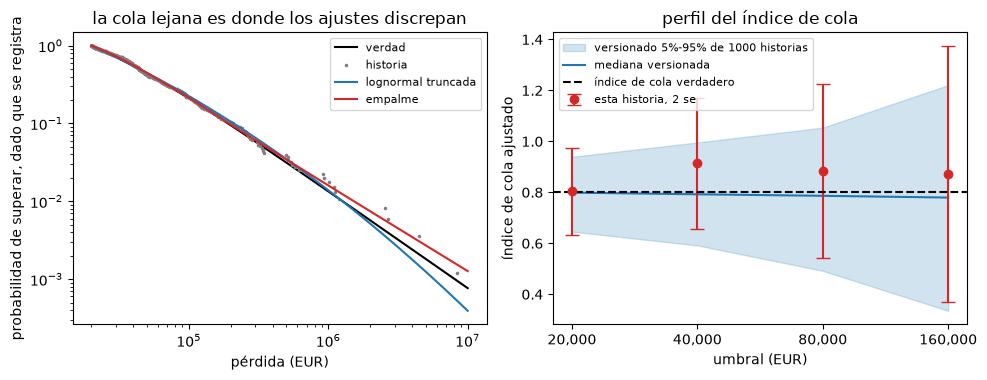

In [13]:
# Draw the survival functions and the tail-index profile
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))
x = np.logspace(np.log10(H), 7, 200)
left.loglog(x, (1.0 - distributions.severity_cdf("gpd", variant.sev_params, x)) / (1.0 - float(distributions.severity_cdf("gpd", variant.sev_params, np.array([H]))[0])), color="black", label="verdad")
sorted_losses = np.sort(recorded.amounts)
left.loglog(sorted_losses, 1.0 - (np.arange(1, sorted_losses.size + 1) - 0.5) / sorted_losses.size, ".", color="tab:gray", markersize=3, label="historia")
ln_sf = (1.0 - distributions.severity_cdf("lognormal", fit_truncated.params, x)) / (1.0 - cdf_at_h)
sp_sf = (1.0 - distributions.severity_cdf("lognormal-gpd-splice", fit_splice.params, x)) / (1.0 - float(distributions.severity_cdf("lognormal-gpd-splice", fit_splice.params, np.array([H]))[0]))
left.loglog(x, ln_sf, color="tab:blue", label="lognormal truncada")
left.loglog(x, sp_sf, color="tab:red", label="empalme")
left.set_xlabel("pérdida (EUR)")
left.set_ylabel("probabilidad de superar, dado que se registra")
left.set_title("la cola lejana es donde los ajustes discrepan")
left.legend(fontsize=8)

committed_median = [row["tail_index"]["median"] for row in cell["threshold_stability"]]
committed_low = [row["tail_index"]["p05"] for row in cell["threshold_stability"]]
committed_high = [row["tail_index"]["p95"] for row in cell["threshold_stability"]]
right.fill_between(range(4), committed_low, committed_high, color="tab:blue", alpha=0.2, label="versionado 5%-95% de 1000 historias")
right.plot(range(4), committed_median, color="tab:blue", label="mediana versionada")
right.errorbar(range(4), profile.xi, yerr=2 * profile.xi_se, fmt="o", color="tab:red", capsize=5, label="esta historia, 2 se")
right.axhline(variant.tail_index, color="black", linestyle="--", label="índice de cola verdadero")
right.set_xticks(range(4))
right.set_xticklabels([format(int(u), ",") for u in profile.thresholds])
right.set_xlabel("umbral (EUR)")
right.set_ylabel("índice de cola ajustado")
right.set_title("perfil del índice de cola")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **La calibración.** Ajustando solo la escala, el mayor error logarítmico absoluto frente a los cuatro percentiles de la LDCE es 0,447, 0,215, 0,038 y 0,160 para los índices de cola 0,6, 0,8, 0,96 y 1,1. El índice cercano a 0,96 es el que sugieren los propios percentiles, y por eso el caso corre una variante ahí; el recálculo con el motor reproduce los errores registrados con cuatro decimales.
- **Lo que un banco registra.** De las 673 pérdidas sufridas en diez años, el banco registra 422 sobre EUR 20.000. La tasa Poisson es 42,2 al año con error estándar 2,05, frente a un valor verdadero de 41,0.
- **Ignorar el umbral.** La lognormal ajustada como si las pérdidas registradas fueran todas las pérdidas (mu 10,96, sigma 0,94) implica una mediana de EUR 57.379 donde la mediana muestral es EUR 43.962, y en la cola es demasiado delgada: la probabilidad de una pérdida sobre EUR 500.000 es 0,0104 frente a 0,0379 registrado, sobre EUR 1.000.000 es 0,0011 frente a un valor verdadero de 0,0134, y sobre EUR 5.000.000 es cero con cinco decimales frente a 0,0018.
- **Modelar el umbral.** La lognormal truncada (mu 5,80 con error estándar 2,60, sigma 2,51 con 0,55) tiene la mayor log-verosimilitud, -5.064,9 frente a -5.195,2, y su mediana de EUR 44.298 coincide con los datos. Sus parámetros están mal determinados, y la tasa reescalada es de 823 pérdidas al año porque solo el 5,1% de la ley ajustada queda sobre el umbral; las 71,97 pérdidas anuales implícitas sobre EUR 10.000 se comparan con un valor verdadero de 65,28.
- **La cola.** El ajuste Pareto generalizado da un índice de cola de 0,8035 con error estándar 0,086, frente a un valor verdadero de 0,80. En EUR 5.000.000, donde una historia casi no tiene observaciones, la probabilidad de superar es 0,0018 en la verdad: la Pareto generalizada da 0,0020, la lognormal truncada la subestima con 0,0012 y el empalme, cuyo índice de cola es 0,911, la sobrestima con 0,0027.
- **El perfil.** El índice de cola ajustado es 0,80, 0,91, 0,88 y 0,87 en los umbrales EUR 20.000 a 160.000, un rango de 0,110 que `oprisk.threshold_stability` colorea ámbar (el verde exige 0,10 o menos). Sobre 1.000 historias de la celda la mediana se mantiene cerca de 0,78 a 0,80 mientras la banda de 5% a 95% se ensancha de 0,65 a 0,94 en el umbral más bajo a 0,34 a 1,22 en el más alto.
- **La estabilidad.** En doce historias consecutivas la ubicación de la lognormal truncada va de -354.374 a 8,32, y el peso del empalme es exactamente 1 en cinco de ellas, señal de que el cuerpo no se puede identificar con las pérdidas sobre el umbral. Los documentos versionados coinciden: con índice de cola 0,96 la lognormal truncada está definida en 723 de 1.000 historias de la celda y el empalme en 572; con 1,1, en 205 y 409.
- **Qué motor.** Los documentos versionados los calculó riskvalidation 0.7.0 y este cuaderno corre la 0.8.1; el recálculo de los cuantiles ajustados de la LDCE coincide con el documento, y los ajustes de una historia son cálculos nuevos sobre una historia regenerada desde su semilla.

Lo que este cuaderno no muestra: cómo las severidades ajustadas se convierten en un capital (cuaderno 03), la aproximación de forma cerrada (cuaderno 04) o la combinación con escenarios de expertos (cuaderno 05).

## Resumen

- Un banco registra solo las pérdidas sobre su umbral de recolección: ajusta una severidad truncada y reescala la frecuencia por uno sobre la supervivencia en el umbral, o el capital queda sesgado.
- Los ajustes truncados de una cola pesada están mal determinados: un cuerpo lognormal puede colapsar, el peso del empalme puede llegar a 1, y los peldaños que los necesitan quedan indefinidos en muchas historias.
- El perfil del índice de cola y `oprisk.threshold_stability` leen cómo deriva el índice de cola con el umbral; sus umbrales de decisión son propios de Contraste.
- El índice de cola de 0,96 del generador es el más cercano a los cuatro percentiles de la LDCE, y el caso lo lee como una variante, no como un hallazgo sobre bancos.

**Qué probar a continuación.** Cambia `SEED` y `H` (10.000 frente a 20.000) y mira el número de pérdidas registradas y el ancho del perfil. Luego reemplaza el umbral de empalme por EUR 50.000 y cuenta cuántas de las doce historias dan un peso de 1. Sigue con el cuaderno 03.

## Referencias

- BCBS (2009), Results from the 2008 Loss Data Collection Exercise for Operational Risk, Comité de Supervisión Bancaria de Basilea. https://www.bis.org/publ/bcbs160.htm
- Chavez-Demoulin, V., Embrechts, P. y Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008
- Mignola, G. y Ugoccioni, R. (2007), Effect of a data collection threshold in the loss distribution approach, Journal of Operational Risk 1(4), 35-47. https://doi.org/10.21314/JOP.2006.019